In [11]:

from pathlib import Path
import pandas as pd

PROJECT = Path("/kaggle/working/ubiris_v2_project")

print("NOTEBOOK 12 — MEMBERSHIP INFERENCE SETUP")
print("=" * 65)

checks = {
    "Baseline checkpoint":
        PROJECT / "UBIRIS_V2_baseline_resnet18_best.pth",
    "Augmented model checkpoint":
        PROJECT / "notebook10_augmented_recognition/UBIRIS_V2_augmented_resnet18_best.pth",
    "Training split":
        PROJECT / "UBIRIS_V2_train_split.csv",
    "Validation split":
        PROJECT / "UBIRIS_V2_validation_split.csv",
    "Test split":
        PROJECT / "UBIRIS_V2_test_split.csv",
    "Preprocessed metadata":
        PROJECT / "notebook02_preprocessing/UBIRIS_V2_preprocessed_metadata.csv",
}

for name, path in checks.items():
    print(f"\n{name}: {'FOUND' if path.is_file() else 'MISSING'}")
    if path.is_file():
        print(" Path:", path)
        print(" Size:", f"{path.stat().st_size:,} bytes")

for name in ["Training split", "Test split"]:
    path = checks[name]
    if path.is_file():
        df = pd.read_csv(path)
        print(f"\n{name} columns:", df.columns.tolist())
        print(f"{name} shape:", df.shape)
        print(df.head(3).to_string(index=False))

print("\nSetup inspection complete.")


NOTEBOOK 12 — MEMBERSHIP INFERENCE SETUP

Baseline checkpoint: FOUND
 Path: /kaggle/working/ubiris_v2_project/UBIRIS_V2_baseline_resnet18_best.pth
 Size: 45,297,675 bytes

Augmented model checkpoint: FOUND
 Path: /kaggle/working/ubiris_v2_project/notebook10_augmented_recognition/UBIRIS_V2_augmented_resnet18_best.pth
 Size: 45,297,291 bytes

Training split: FOUND
 Path: /kaggle/working/ubiris_v2_project/UBIRIS_V2_train_split.csv
 Size: 1,006,063 bytes

Validation split: FOUND
 Path: /kaggle/working/ubiris_v2_project/UBIRIS_V2_validation_split.csv
 Size: 182,634 bytes

Test split: FOUND
 Path: /kaggle/working/ubiris_v2_project/UBIRIS_V2_test_split.csv
 Size: 183,239 bytes

Preprocessed metadata: FOUND
 Path: /kaggle/working/ubiris_v2_project/notebook02_preprocessing/UBIRIS_V2_preprocessed_metadata.csv
 Size: 858,104 bytes

Training split columns: ['filename', 'relative_path', 'processed_path', 'subject', 'session', 'image_id', 'original_width', 'original_height', 'processed_width', 'proc

Notebook 12 — Membership Inference Attack
Device: cuda
Usable members: 4243
Usable non-members: 778
Classes: 260

Evaluating: baseline
  Attack ROC-AUC: 0.4929
  Member mean loss: 12.0663
  Non-member mean loss: 11.9397

Evaluating: augmented
  Attack ROC-AUC: 0.5168
  Member mean loss: 13.9285
  Non-member mean loss: 14.3301


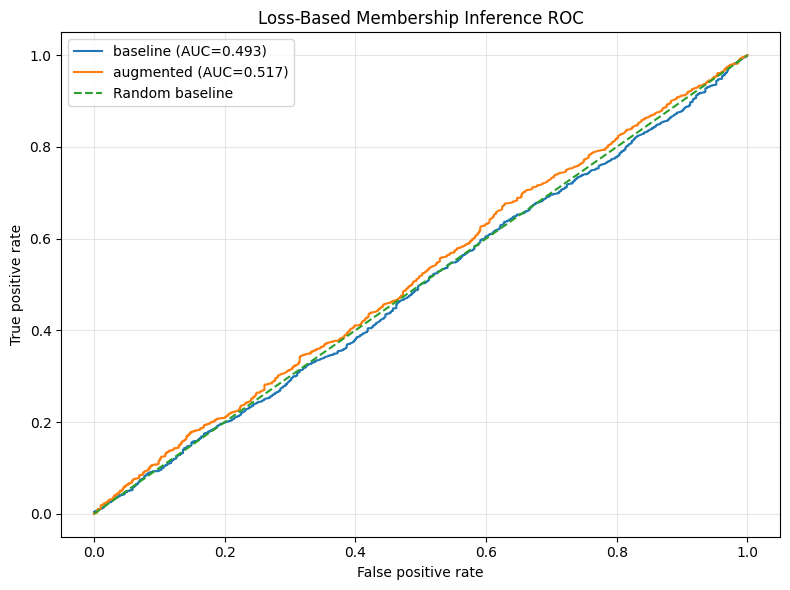

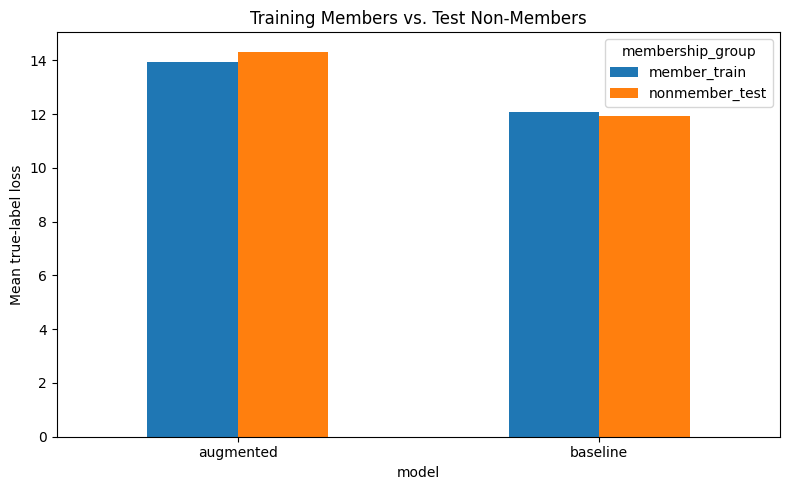


OUTPUT VERIFICATION
OK       UBIRIS_V2_membership_group_scores.csv
OK       UBIRIS_V2_membership_attack_summary.csv
OK       UBIRIS_V2_membership_attack_summary.json
OK       UBIRIS_V2_membership_attack_roc.png
OK       UBIRIS_V2_member_nonmember_loss.png
OK       Notebook12_Conclusion.md

FINAL ATTACK SUMMARY
    model  members  nonmembers  member_mean_loss  nonmember_mean_loss  member_mean_confidence  nonmember_mean_confidence  member_prediction_accuracy  nonmember_prediction_accuracy  attack_roc_auc  attack_accuracy_at_selected_threshold  attack_precision  attack_recall  attack_f1  threshold_selected_on_evaluation_set                                                                                                 threshold_selection_note
 baseline     4243         778         12.066297            11.939719                0.004778                   0.003845                    0.004478                       0.001285        0.492923                               0.595499          0.846

/kaggle/working/ubiris_v2_project/UBIRIS_V2_Notebook12_Results.zip

In [12]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import FileLink, display

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score,
    precision_score, recall_score, f1_score
)

# =========================================================
# 0. Configuration
# =========================================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PROJECT = Path("/kaggle/working/ubiris_v2_project")
PRE_DIR = PROJECT / "notebook02_preprocessing"
OUT_DIR = PROJECT / "notebook12_membership_inference"
OUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = PROJECT / "UBIRIS_V2_train_split.csv"
TEST_CSV = PROJECT / "UBIRIS_V2_test_split.csv"

CHECKPOINTS = {
    "baseline": PROJECT / "UBIRIS_V2_baseline_resnet18_best.pth",
    "augmented": PROJECT / "notebook10_augmented_recognition"
                 / "UBIRIS_V2_augmented_resnet18_best.pth",
}

for p in [TRAIN_CSV, TEST_CSV, *CHECKPOINTS.values()]:
    if not p.is_file():
        raise FileNotFoundError(f"Required file missing: {p}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Notebook 12 — Membership Inference Attack")
print("=" * 65)
print("Device:", device)

# =========================================================
# 1. Load membership/non-membership data
# =========================================================
train_df = pd.read_csv(TRAIN_CSV).copy()
test_df = pd.read_csv(TEST_CSV).copy()

def resolve_image_path(row):
    # Recovered files may retain their absolute paths from the old runtime.
    candidates = [
        Path(str(row.get("image_path", ""))),
        Path(str(row.get("processed_path", ""))),
        PRE_DIR / "images_224" / (Path(str(row["filename"])).stem + ".png"),
    ]
    for p in candidates:
        if str(p) not in ("", ".") and p.is_file():
            return p
    return None

train_df["resolved_path"] = train_df.apply(resolve_image_path, axis=1)
test_df["resolved_path"] = test_df.apply(resolve_image_path, axis=1)

train_df = train_df[train_df["resolved_path"].notna()].reset_index(drop=True)
test_df = test_df[test_df["resolved_path"].notna()].reset_index(drop=True)

if len(train_df) == 0 or len(test_df) == 0:
    raise RuntimeError(
        "No usable images found. The recovered split CSVs reference the old "
        "runtime paths; restore the preprocessed images into notebook02_preprocessing/images_224."
    )

# Use original grayscale 224x224 preprocessed images.
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

class IrisDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row["resolved_path"]) as im:
            image = im.convert("L")
            x = transform(image)
        return x, int(row["label"])

def make_model(num_classes):
    model = models.resnet18(weights=None)
    model.conv1 = nn.Conv2d(
        1, 64, kernel_size=7, stride=2, padding=3, bias=False
    )
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

def load_checkpoint(path, num_classes):
    model = make_model(num_classes)
    state = torch.load(path, map_location="cpu", weights_only=False)

    # Support either a raw state dict or a checkpoint dictionary.
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    elif isinstance(state, dict) and "model_state_dict" in state:
        state = state["model_state_dict"]

    if not isinstance(state, dict):
        raise RuntimeError(f"Unrecognized checkpoint format: {path}")

    # Handle DataParallel state-dict prefixes if present.
    state = {
        (k[7:] if k.startswith("module.") else k): v
        for k, v in state.items()
    }
    model.load_state_dict(state)
    return model.to(device).eval()

num_classes = int(
    max(train_df["label"].max(), test_df["label"].max()) + 1
)

print(f"Usable members: {len(train_df)}")
print(f"Usable non-members: {len(test_df)}")
print(f"Classes: {num_classes}")

# =========================================================
# 2. Calculate per-image loss and confidence
# =========================================================
def collect_scores(model, frame, batch_size=64):
    loader = DataLoader(
        IrisDataset(frame), batch_size=batch_size,
        shuffle=False, num_workers=2,
        pin_memory=(device.type == "cuda")
    )

    losses, confidences, correct_flags = [], [], []
    criterion = nn.CrossEntropyLoss(reduction="none")

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                logits = model(images)
                batch_losses = criterion(logits, labels)

            probs = torch.softmax(logits.float(), dim=1)
            true_conf = probs.gather(1, labels.unsqueeze(1)).squeeze(1)
            preds = logits.argmax(dim=1)

            losses.extend(batch_losses.float().cpu().numpy())
            confidences.extend(true_conf.cpu().numpy())
            correct_flags.extend((preds == labels).cpu().numpy())

    return (
        np.asarray(losses),
        np.asarray(confidences),
        np.asarray(correct_flags, dtype=bool)
    )

all_results = []
summary_rows = []
roc_curves = {}
start_time = time.time()

for model_name, checkpoint in CHECKPOINTS.items():
    print(f"\nEvaluating: {model_name}")

    model = load_checkpoint(checkpoint, num_classes)

    member_loss, member_conf, member_correct = collect_scores(
        model, train_df
    )
    nonmember_loss, nonmember_conf, nonmember_correct = collect_scores(
        model, test_df
    )

    # Attack score: lower true-label loss means more likely a member.
    y_true = np.concatenate([
        np.ones(len(member_loss), dtype=int),
        np.zeros(len(nonmember_loss), dtype=int)
    ])
    attack_score = np.concatenate([-member_loss, -nonmember_loss])

    auc = float(roc_auc_score(y_true, attack_score))
    fpr, tpr, thresholds = roc_curve(y_true, attack_score)

    # Choose a threshold using the same evaluation set; descriptive only.
    best_idx = int(np.argmax(tpr - fpr))
    threshold = float(thresholds[best_idx])
    attack_pred = (attack_score >= threshold).astype(int)

    attack_acc = float(accuracy_score(y_true, attack_pred))
    attack_precision = float(
        precision_score(y_true, attack_pred, zero_division=0)
    )
    attack_recall = float(
        recall_score(y_true, attack_pred, zero_division=0)
    )
    attack_f1 = float(
        f1_score(y_true, attack_pred, zero_division=0)
    )

    rows = []
    for membership, losses, confs, correct in [
        ("member_train", member_loss, member_conf, member_correct),
        ("nonmember_test", nonmember_loss, nonmember_conf, nonmember_correct)
    ]:
        rows.append({
            "model": model_name,
            "membership_group": membership,
            "sample_count": len(losses),
            "mean_true_label_loss": float(np.mean(losses)),
            "median_true_label_loss": float(np.median(losses)),
            "mean_true_label_confidence": float(np.mean(confs)),
            "prediction_accuracy": float(np.mean(correct)),
        })

    all_results.extend(rows)
    roc_curves[model_name] = (fpr, tpr, auc)

    summary_rows.append({
        "model": model_name,
        "members": len(member_loss),
        "nonmembers": len(nonmember_loss),
        "member_mean_loss": float(np.mean(member_loss)),
        "nonmember_mean_loss": float(np.mean(nonmember_loss)),
        "member_mean_confidence": float(np.mean(member_conf)),
        "nonmember_mean_confidence": float(np.mean(nonmember_conf)),
        "member_prediction_accuracy": float(np.mean(member_correct)),
        "nonmember_prediction_accuracy": float(np.mean(nonmember_correct)),
        "attack_roc_auc": auc,
        "attack_accuracy_at_selected_threshold": attack_acc,
        "attack_precision": attack_precision,
        "attack_recall": attack_recall,
        "attack_f1": attack_f1,
        "threshold_selected_on_evaluation_set": threshold,
        "threshold_selection_note":
            "Exploratory threshold selected on evaluated members/non-members; "
            "threshold metrics are not an independent test estimate."
    })

    print(f"  Attack ROC-AUC: {auc:.4f}")
    print(f"  Member mean loss: {np.mean(member_loss):.4f}")
    print(f"  Non-member mean loss: {np.mean(nonmember_loss):.4f}")

    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()

# =========================================================
# 3. Save results and plots
# =========================================================
scores_df = pd.DataFrame(all_results)
summary_df = pd.DataFrame(summary_rows)

scores_df.to_csv(
    OUT_DIR / "UBIRIS_V2_membership_group_scores.csv", index=False
)
summary_df.to_csv(
    OUT_DIR / "UBIRIS_V2_membership_attack_summary.csv", index=False
)

plt.figure(figsize=(8, 6))
for name, (fpr, tpr, auc) in roc_curves.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Loss-Based Membership Inference ROC")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "UBIRIS_V2_membership_attack_roc.png", dpi=160)
plt.show()
plt.close()

# Compare mean loss and confidence for members vs non-members.
plot_df = scores_df.pivot(
    index="model", columns="membership_group",
    values="mean_true_label_loss"
)
plot_df.plot(kind="bar", figsize=(8, 5))
plt.ylabel("Mean true-label loss")
plt.title("Training Members vs. Test Non-Members")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT_DIR / "UBIRIS_V2_member_nonmember_loss.png", dpi=160)
plt.show()
plt.close()

summary_json = {
    "experiment": "Loss-based membership inference",
    "dataset": "UBIRIS V2",
    "score_definition": "Negative true-label cross-entropy loss; higher means more member-like",
    "member_source": "Original training split",
    "nonmember_source": "Original test split",
    "train_images_evaluated": int(len(train_df)),
    "test_images_evaluated": int(len(test_df)),
    "num_classes": num_classes,
    "runtime_seconds": round(time.time() - start_time, 2),
    "model_results": summary_rows,
    "limitations": [
        "The split is image-level, not subject-disjoint; identities may occur in both groups.",
        "Threshold metrics use a threshold selected on the evaluated groups and are exploratory.",
        "AUC near 0.5 indicates little separation by this attack score; it does not prove privacy.",
        "AUC above 0.5 indicates score-based membership distinguishability under this setup, not a confirmed biometric privacy breach.",
        "This is a loss-based attack only; it does not establish identity reconstruction or real-world attacker capability."
    ]
}
with open(OUT_DIR / "UBIRIS_V2_membership_attack_summary.json", "w") as f:
    json.dump(summary_json, f, indent=2)

conclusion = """# Notebook 12 — Membership Inference Attack

## Objective
A loss-based membership inference experiment was conducted to investigate
whether the models' true-label losses distinguish training images (members)
from held-out test images (non-members).

## Method
For each saved recognition model, true-label cross-entropy loss and
true-label prediction confidence were measured for training and test images.
The attack score was defined as negative true-label loss, so higher scores
indicate greater member-likeness. ROC-AUC was used to summarize separation.

## Interpretation
Use the generated summary CSV and JSON for the measured results. An AUC near
0.5 indicates little separation by this particular score. A higher AUC indicates
greater distinguishability under this experimental setup. Neither outcome alone
proves or rules out a privacy breach.

## Limitations
The dataset split is image-level, not subject-disjoint, and identities can
appear in both member and non-member groups. The threshold-based accuracy,
precision, recall, and F1 are exploratory because the threshold is selected on
the evaluated groups. This is a limited loss-based attack, not a comprehensive
privacy audit, identity reconstruction test, or proof of real-world leakage.

## Conclusion
The results characterize the degree to which training membership is
distinguishable using true-label loss for the two saved models under this
dataset split. Any privacy interpretation must remain limited to this attack,
these checkpoints, and this evaluation protocol.
"""
(OUT_DIR / "Notebook12_Conclusion.md").write_text(conclusion)

# =========================================================
# 4. Verify and ZIP all Notebook 12 outputs
# =========================================================
required = [
    "UBIRIS_V2_membership_group_scores.csv",
    "UBIRIS_V2_membership_attack_summary.csv",
    "UBIRIS_V2_membership_attack_summary.json",
    "UBIRIS_V2_membership_attack_roc.png",
    "UBIRIS_V2_member_nonmember_loss.png",
    "Notebook12_Conclusion.md",
]

print("\nOUTPUT VERIFICATION")
missing = []
for name in required:
    p = OUT_DIR / name
    ok = p.is_file() and p.stat().st_size > 0
    print(f"{'OK' if ok else 'MISSING':8} {name}")
    if not ok:
        missing.append(name)

if missing:
    raise FileNotFoundError("Missing outputs: " + ", ".join(missing))

zip_path = PROJECT / "UBIRIS_V2_Notebook12_Results.zip"
with ZipFile(zip_path, "w", ZIP_DEFLATED) as zf:
    for p in sorted(OUT_DIR.rglob("*")):
        if p.is_file():
            zf.write(p, arcname=p.relative_to(PROJECT))

with ZipFile(zip_path, "r") as zf:
    bad = zf.testzip()
    if bad:
        raise RuntimeError(f"ZIP integrity error: {bad}")
    archived = zf.namelist()

print("\nFINAL ATTACK SUMMARY")
print(summary_df.to_string(index=False))
print("\nRuntime:", round(time.time() - start_time, 2), "seconds")
print("ZIP:", zip_path)
print("Files archived:", len(archived))
print("ZIP integrity: PASSED")
display(FileLink(str(zip_path)))
